In [1]:
import mne
import numpy as np
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.signal import welch
from torch.utils.data import DataLoader, Dataset
import os
import matplotlib as mpl
import pandas as pd
from datasets import *
from eois import *
import torch
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix)
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
import seaborn as sns
from scipy.stats import median_abs_deviation
import warnings
warnings.filterwarnings(
    "ignore",
    message="This filename.*",
    category=RuntimeWarning,
)
mpl.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({
    'font.size': 7,           # base font size
    'axes.titlesize': 7,      # title of axes
    'axes.labelsize': 7,      # x and y labels
    'xtick.labelsize': 7,     # x tick labels
    'ytick.labelsize': 7,     # y tick labels
    'legend.fontsize': 7,     # legend
    'figure.titlesize': 7,    # figure suptitle
})

In [2]:
def compute_bandpowers(data, fs):
    """
    data: array, shape (n_trials, n_times)
    returns: X, shape (n_trials, 4)
    """
    bands = {
        "theta": (4, 7),
        "alpha": (8, 12),
        "beta": (16, 24),
        "gamma": (30, 40),
    }

    psd, freqs = mne.time_frequency.psd_array_multitaper(data, fs, fmin=0, fmax=50, bandwidth=6*(fs / data.shape[-1]), verbose=False)

    features = []
    for band, (fmin, fmax) in bands.items():
        idx = (freqs >= fmin) & (freqs <= fmax)
        bp = np.trapezoid(psd[:, idx], freqs[idx], axis=1)
        features.append(bp)

    X = np.column_stack(features)
    return X, freqs, psd




def load_model_state(model, state, device):
    clean_state = {}
    for k, v in state.items():
        if k.startswith("module."):
            k = k[len("module."):]
        if k.startswith("model."):
            k = k[len("model."):]
        clean_state[k] = v
    
    # Load weights, move to device, set evaluation mode
    _ = model.load_state_dict(clean_state, strict=True)
    model = model.to(device).eval()
    return model


def summarize(x, style="median[IQR]"):
    x = np.asarray(x, dtype=float).ravel()
    x = x[np.isfinite(x)]
    if x.size == 0:
        return ""
    if style.lower() in ("median[iqr]", "median_iqr", "median[q1,q3]"):
        q1, med, q3 = np.percentile(x, [25, 50, 75])
        return f"{med:.3f} [{q1:.3f}, {q3:.3f}]"
    elif style.lower() in ("mean±sd", "mean+/-sd", "mean_sd"):
        m = float(np.mean(x)); s = float(np.std(x, ddof=1 if x.size > 1 else 0))
        return f"{m:.3f} ± {s:.3f}"
    else:
        raise ValueError("style must be 'median[IQR]' or 'mean±SD'")

def rms_power(signal_2d, start_idx, length):
    end_idx = start_idx + length
    seg = signal_2d[:, start_idx:end_idx]
    return np.sqrt(np.mean(seg**2, axis=1))


def standardize_fit(X_train, X_test):
    mu = X_train.mean(axis=0)
    sd = X_train.std(axis=0)
    return (X_train - mu) / sd, (X_test - mu) / sd

def split_app_train_test(n_appl, test_frac=0.2):
    n_test = int(round(test_frac * n_appl))
    if n_test < 1 or n_test >= n_appl:
        raise ValueError(f"Bad test_frac={test_frac} for n_appl={n_appl}")
    idx_train = slice(0, n_appl - n_test)
    idx_test  = slice(n_appl - n_test, n_appl)
    return idx_train, idx_test, n_test

def make_labels_from_training(y_cal_cont, y_appl_cont, idx_app_train, thresh="median"):
    y_cal_cont = np.asarray(y_cal_cont, float)
    y_appl_cont = np.asarray(y_appl_cont, float)
    # threshold from training targets only (cal + early app)
    y_train_pool = np.concatenate([y_cal_cont, y_appl_cont[idx_app_train]])
    if thresh == "median":
        t = float(np.median(y_train_pool))
    elif isinstance(thresh, (int, float)):
        t = float(thresh)
    else:
        raise ValueError("Unsupported threshold spec")
    # binarize both sets with the same threshold
    y_cal = (y_cal_cont >= t).astype(int)
    y_appl = (y_appl_cont >= t).astype(int)
    return y_cal, y_appl, t

def fit_eval_logreg(X_cal, X_appl, y_cal, y_appl, idx_app_train, idx_app_test, seed=0):
    # Build train/test using provided indices
    X_appl_train, y_appl_train = X_appl[idx_app_train], y_appl[idx_app_train]
    X_test,       y_test       = X_appl[idx_app_test],  y_appl[idx_app_test]

    X_train = np.vstack([X_cal, X_appl_train])
    y_train = np.concatenate([y_cal, y_appl_train])

    X_train_z, X_test_z = standardize_fit(X_train, X_test)

    clf = LogisticRegression(
        C=1.0, l1_ratio=0, solver="lbfgs", max_iter=2000, random_state=seed
    )
    clf.fit(X_train_z, y_train)

    y_pred = clf.predict(X_test_z)
    y_prob = clf.predict_proba(X_test_z)[:, 1]
    majority = np.bincount(y_train).argmax()
    y_null = np.full_like(y_test, majority)

    acc = accuracy_score(y_test, y_pred)
    bal = balanced_accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred)
    try:
        auc = roc_auc_score(y_test, y_prob)
    except ValueError:
        auc = np.nan

    cm = confusion_matrix(y_test, y_pred)
    metrics = dict(acc=acc, bal_acc=bal, f1=f1, auc=auc,
                   n_train=len(y_train), n_test=len(y_test), cm=cm)
    return clf, metrics, y_test, y_pred, y_prob, y_null



In [3]:
root = os.path.join("/scratch/work/aholao1/", "reftep_processed")
subjects = sorted([s for s in os.listdir(root) if os.path.isdir(os.path.join(root, s)) and "sub" in s])
feature_names = ["theta", "alpha", "beta", "gamma"]
test_frac = 0.2
#windows_ms_k = (offset_from_start_k, length_k)
windows_ms = [(0, 50),(50, 125),(0, 275)]
style = "median[IQR]"
seed = 0
models_path = "models/TMS_time_[-0.5, 0.5]_models_v"
applying_times = {sub: [] for sub in subjects}

summary_rows = []   # per subject/window/model: calibration/application summaries
metrics_rows = []   # per subject/window/model: classification metrics
coef_rows = []      # per subject/window/model/feature: classifier coefficients
ongoing_induced_corrs = []
evoked_corrs = []
original_corrs = []
evoked_ongoing_induced_corrs = []
# construct models for each subject

for subject in subjects:
    print(f"Running for {subject}")
    model_file = [f for f in os.listdir(models_path) if subject in f and "final" in f][0]

    # Read data
    calibration_data_teps, _, times_post = read_preprocessed_tep_epochs(
        subject, root, "calibration", [-0.5, 0.5], "C3"
    )
    calibration_data_prestim, fs, times_pre = read_preprocessed_prestim_epochs(
        subject, root, "calibration", [-0.505, None], "C3"
    )
    application_data_teps, _, _ = read_preprocessed_tep_epochs(
        subject, root, "application", [-0.5, 0.5], "C3"
    )
    application_data_prestim, _, _ = read_preprocessed_prestim_epochs(
        subject, root, "application", [-0.505, None], "C3"
    )

    # Indices
    
    t_sample_min_post = int(np.min(np.where(times_post >= 0.025)))
    t_sample_max_norm = int(np.max(np.where(times_post <= -0.1)))

    # Pre-stim features (bandpowers, log-transform)
    X_cal = compute_bandpowers(calibration_data_prestim, fs)
    X_appl = compute_bandpowers(application_data_prestim, fs)
    if isinstance(X_cal, tuple): X_cal = X_cal[0]
    if isinstance(X_appl, tuple): X_appl = X_appl[0]
    X_cal = np.log(np.asarray(X_cal, dtype=float))
    X_appl = np.log(np.asarray(X_appl, dtype=float))
    if X_cal.shape[1] != len(feature_names):
        raise ValueError(f"{subject}: expected {len(feature_names)} features, got {X_cal.shape[1]}")

    # Evoked/Induced separation
    data = np.concatenate([calibration_data_teps, application_data_teps], axis=0)
    n_cal = calibration_data_teps.shape[0]
    n_app = application_data_teps.shape[0]

    model = EvokedOngoingInducedSeparator()
    subject_id = torch.tensor(np.full(data.shape[0], int(model_file.split("_")[2]) , dtype=np.int64))
    test_loader = DataLoader(NeuroDataset(data, subject_id), batch_size=1)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

     # Load state_dict from the checkpoint and strip common prefixes
    bundle = torch.load(os.path.join(models_path, model_file), map_location="cpu")
    state = bundle["model"]  # OrderedDict
    clean_state = {}
    for k, v in state.items():
        if k.startswith("module."):
            k = k[len("module."):]
        if k.startswith("model."):
            k = k[len("model."):]
        clean_state[k] = v
    
    # Load weights, move to device, set evaluation mode
    _ = model.load_state_dict(clean_state, strict=True)
    model = model.to(device).eval()

    es = []
    us = []
    # time trial by trial applying
    with torch.no_grad():
        for i, (xb, _) in enumerate(test_loader):
            xb = xb.to(device, dtype=torch.float32)
            t0 = time.perf_counter()
            E, U = model(xb)
            applying_times[subject].append(time.perf_counter() - t0)
            es.append(E)
            us.append(U)
        es = torch.stack(es, dim=0).squeeze()
        us = torch.stack(us, dim=0).squeeze()
    E = es.cpu().numpy()
    U = us.cpu().numpy()
    print(r2_score(np.mean(data[:n_cal],axis=0)[500:800],np.mean(E[:n_cal],axis=0)[500:800]))

    calibration_E = E[:n_cal, :]
    calibration_U = U[:n_cal, :]
    application_E = E[n_cal:n_cal+n_app, :]
    application_U = U[n_cal:n_cal+n_app, :]

    models = {
        "Unseparated": {"cal": calibration_data_teps, "app": application_data_teps},
        "Evoked":   {"cal": calibration_E,         "app": application_E},
        "Ongoing/Induced":   {"cal": calibration_U,         "app": application_U},
    }

    evoked_rms = np.sqrt(np.mean(np.concatenate([models['Evoked']['cal'][:,t_sample_min_post:],
                                                       models['Evoked']['app'][:,t_sample_min_post:]])**2,axis=1))
    ongoing_induced_rms = np.sqrt(np.mean(np.concatenate([models['Ongoing/Induced']['cal'][:,t_sample_min_post:],
                                                        models['Ongoing/Induced']['app'][:,t_sample_min_post:]])**2,axis=1))
    original_rms = np.sqrt(np.mean(np.concatenate([models['Unseparated']['cal'][:,t_sample_min_post:],
                                                        models['Unseparated']['app'][:,t_sample_min_post:]])**2,axis=1))
    pre_stim_rms = np.sqrt(np.mean(np.concatenate([calibration_data_prestim,application_data_prestim])**2, axis=1))
    evoked_corrs.append(np.corrcoef(evoked_rms, pre_stim_rms)[0, 1])
    ongoing_induced_corrs.append(np.corrcoef(ongoing_induced_rms, pre_stim_rms)[0, 1])
    original_corrs.append(np.corrcoef(original_rms, pre_stim_rms)[0, 1])
    evoked_ongoing_induced_corrs.append(np.corrcoef(ongoing_induced_rms, evoked_rms)[0, 1])
    # Loop windows and models
    for (L_start, L_ms) in windows_ms:
        for model_name, dset in models.items():
            # Continuous targets
            y_cal_cont = rms_power(dset["cal"], start_idx=t_sample_min_post + L_start, length=L_ms)
            y_app_cont = rms_power(dset["app"], start_idx=t_sample_min_post + L_start, length=L_ms)
            win_name = f'{25 + L_start}–{25 + L_start + L_ms}'
            
            # Summaries
            summary_rows.append({
                "subject": subject, "window_ms": win_name, "model": model_name,
                "calibration": summarize(y_cal_cont, style=style),
                "application": summarize(y_app_cont, style=style),
                "N_cal": len(y_cal_cont), "N_app": len(y_app_cont),
            })

            # Chronological split indices for application
            idx_app_train, idx_app_test, n_test = split_app_train_test(X_appl.shape[0], test_frac=test_frac)
            
            # Binary labels using TRAINING targets only (cal + early application)
            y_cal, y_app, thr = make_labels_from_training(y_cal_cont, y_app_cont, idx_app_train, thresh="median")
            
            # Sanity: sizes
            if X_cal.shape[0] != len(y_cal) or X_appl.shape[0] != len(y_app):
                raise ValueError(f"{subject} {model_name} {L_ms}ms: X/y mismatch")
            
            
            # Fit logistic regression using the same split indices
            clf, mets, y_test, y_pred, y_prob, y_null = fit_eval_logreg(
                X_cal, X_appl, y_cal, y_app, idx_app_train=idx_app_train, idx_app_test=idx_app_test, seed=seed
            )


            # Metrics row
            metrics_rows.append({
                "subject": subject, "window_ms": win_name, "model": model_name,
                "threshold": thr, "n_train": mets["n_train"], "n_test": mets["n_test"],
                "accuracy": mets["acc"], "balanced_accuracy": mets["bal_acc"],
                "f1": mets["f1"], "auc": mets["auc"],
                "cm": mets["cm"],
            })

            # Coefficients row(s)
            for j, fname in enumerate(feature_names):
                coef_rows.append({
                    "subject": subject, "window_ms": win_name, "model": model_name,
                    "feature": fname, "coef": clf.coef_[0, j], "intercept": clf.intercept_[0],
                })

# ------------------ outputs ------------------

summary_df = pd.DataFrame(summary_rows).set_index(["subject", "window_ms", "model"])
metrics_df = pd.DataFrame(metrics_rows).set_index(["subject", "window_ms", "model"])
coefs_df = pd.DataFrame(coef_rows)  # columns: subject, window_ms, model, feature, coef, intercept

#print("\n=== Summary (per subject/window/model): median [Q1, Q3] of window energy ===")
#print(summary_df[["calibration", "application", "N_cal", "N_app"]].to_string())

#print("\n=== Metrics (per subject/window/model) ===")
#print(metrics_df[["threshold", "n_train", "n_test", "accuracy", "balanced_accuracy", "f1", "auc"]].to_string())

#print("\n=== Coefficients (head) ===")
#print(coefs_df.reset_index().to_string(index=False))

# Aggregates
agg = (metrics_df
       .reset_index()
       .groupby(["model", "window_ms"])
       .agg(accuracy_mean=("accuracy","mean"),
            accuracy_sd=("accuracy","std"),
            bal_mean=("balanced_accuracy","mean"),
            bal_sd=("balanced_accuracy","std"),
            f1_mean=("f1","mean"),
            f1_sd=("f1","std"),
            auc_mean=("auc","mean"),
            auc_sd=("auc","std"),
            n_subj=("subject","nunique"))
       .reset_index())

coef_agg = (coefs_df
            .reset_index()
            .groupby(["model","window_ms","feature"])
            .agg(coef_mean=("coef","mean"),
                 coef_sd=("coef","std"),
                 frac_pos=("coef", lambda x: float(np.mean(x > 0))))
            .reset_index())

Running for sub-018
0.9944221285997215
Running for sub-019
0.9789444073519035
Running for sub-020
0.9234176971177723
Running for sub-021
0.9711359357844351
Running for sub-022
0.9064265102985826
Running for sub-023
0.7638178918745218
Running for sub-024
0.9720761794975246
Running for sub-025
0.9701590722780771
Running for sub-026
0.9872723356465433
Running for sub-027
0.9106248246381974
Running for sub-028
0.9803883810163964
Running for sub-029
0.94565926256987
Running for sub-031
0.9758839620293875
Running for sub-032
0.989351315338906
Running for sub-034
0.98051265985043
Running for sub-035
0.9759128950567991
Running for sub-036
0.9896430732143416
Running for sub-038
0.9730298345228132
Running for sub-039
0.9904118513514613
Running for sub-040
0.9718747652051809
Running for sub-041
0.9169173891597089
Running for sub-042
0.9322136407389687
Running for sub-043
0.9489796441488079
Running for sub-044
0.9764243569741097
Running for sub-045
0.9665112418201706
Running for sub-046
0.95734938

0.12291897775423608 0.11485573453857799
0.40433292368554585 0.15076170024451802
0.15380130287892782 0.13768481320071851
0.31843112746688984 0.14541116218347241
Application times: 14.11680446472019 pm 0.06199302151799202 ms
          model    mean ± std  count
         Evoked 0.557 ± 0.063    156
Ongoing/Induced 0.685 ± 0.082    156
    Unseparated 0.582 ± 0.072    156
window_ms           model    mean ± std  count
   25–300          Evoked 0.569 ± 0.066     52
   25–300 Ongoing/Induced 0.694 ± 0.077     52
   25–300     Unseparated 0.597 ± 0.077     52
    25–75          Evoked 0.549 ± 0.064     52
    25–75 Ongoing/Induced 0.663 ± 0.083     52
    25–75     Unseparated 0.563 ± 0.065     52
   75–200          Evoked 0.552 ± 0.059     52
   75–200 Ongoing/Induced 0.696 ± 0.082     52
   75–200     Unseparated 0.584 ± 0.070     52


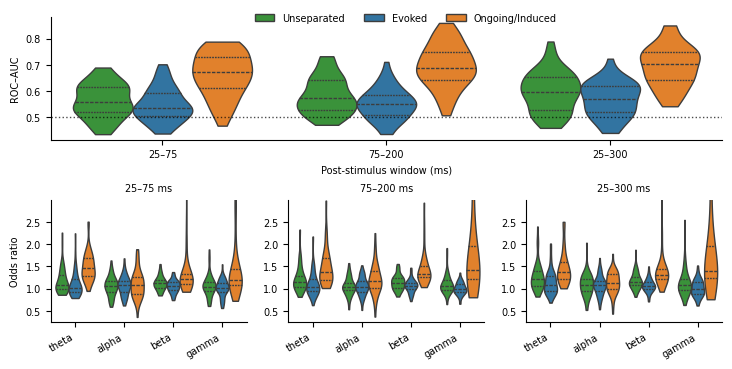

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
for lst in [evoked_corrs, ongoing_induced_corrs, evoked_ongoing_induced_corrs, original_corrs]:
    print(np.mean(lst), np.std(lst))
# application times
all_times = [t for ts in applying_times.values() for t in ts]
print(f"Application times: {np.median(all_times)*1000} pm {median_abs_deviation(all_times)*1000} ms")

# Data
subj_metrics = metrics_df.reset_index()  # columns: subject, window_ms, model, auc
coefs = coefs_df.copy()                  # columns: subject, window_ms, model, feature, coef, intercept

# Transform coefficients into odds ratios
coefs["odds_ratio"] = np.exp(coefs["coef"])

# Figure layout
wins = subj_metrics["window_ms"].unique()
n_win = len(wins)


per_subject = (
    subj_metrics
    .groupby(['subject', 'window_ms', 'model'])['auc']
    .mean()
    .reset_index()
)
#  mean ± std across subjects
summary = (
    per_subject
    .groupby(['window_ms', 'model'])['auc']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .sort_values(['window_ms', 'model'])
)

per_model = (
    per_subject
    .groupby('model')['auc']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .sort_values('model')
)

per_model['mean ± std'] = per_model['mean'].map('{:.3f}'.format) + ' ± ' + per_model['std'].map('{:.3f}'.format)
print(per_model[['model', 'mean ± std', 'count']].to_string(index=False))
summary['mean ± std'] = summary['mean'].map('{:.3f}'.format) + ' ± ' + summary['std'].map('{:.3f}'.format)
print(summary[['window_ms', 'model', 'mean ± std', 'count']].to_string(index=False))


fig = plt.figure(figsize=(7.204, 3.5), constrained_layout=True)
from matplotlib.gridspec import GridSpec
# 2 rows: AUC, odds ratio violins
gs = GridSpec(2, n_win, figure=fig, height_ratios=[1.0, 1.0])

# Top: AUC violins (one axis spanning all columns)
ax_top = fig.add_subplot(gs[0, :])
sns.violinplot(
    data=subj_metrics,
    x="window_ms", y="auc", hue="model",
    cut=0, density_norm='width', inner="quartile", linewidth=1, ax=ax_top,
    palette=['#2ca02c', '#1f77b4', '#ff7f0e']
)
ax_top.axhline(0.5, color="k", ls="dotted", lw=1, alpha=0.7)
ax_top.set_xlabel("Post-stimulus window (ms)")
ax_top.set_ylabel("ROC–AUC")

# Bottom: Odds ratio violins, one subplot per window
axes_mid = []
for i, w in enumerate(wins):
    ax = fig.add_subplot(gs[1, i])
    axes_mid.append(ax)
    sub = coefs[coefs["window_ms"] == w].copy()
    sns.violinplot(
        data=sub, x="feature", y="odds_ratio", hue="model",
        order=["theta", "alpha", "beta", "gamma"],
        cut=0, inner="quartile", density_norm='width',
        linewidth=1, ax=ax,
        palette=['#2ca02c', '#1f77b4', '#ff7f0e']
    )
    #ax.axhline(1, color="k", ls="dotted", lw=1)  # Reference line at odds ratio = 1
    ax.set_ylim([0.25, 3.0])
    ax.set_yticks([0.5, 1, 1.5, 2, 2.5])
    ax.set_xlabel("")
    if i == 0:
        ax.set_ylabel("Odds ratio")
    else:
        ax.set_ylabel("")
    ax.set_title(f"{w} ms")
    for label in ax.get_xticklabels():
        label.set_rotation(30)
        label.set_ha("right")

# Hide upper and right spines on all axes
for ax in [ax_top] + axes_mid:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.set_ticks_position('left')
    ax.xaxis.set_ticks_position('bottom')

# Build a single legend (use handles from top axis)
handles, labels = ax_top.get_legend_handles_labels()
n_models = subj_metrics["model"].nunique()
leg = fig.legend(
    handles[:n_models], labels[:n_models],
    loc="upper center", bbox_to_anchor=(0.555, 1.025),
    frameon=False, ncol=3,
)
# Remove individual legends on subplots
if ax_top.get_legend() is not None:
    ax_top.get_legend().remove()
for ax in axes_mid:
    lg = ax.get_legend()
    if lg is not None:
        lg.remove()

fig.savefig("fig_3_ahola.pdf", dpi=300)
plt.show()
